# Evaluate one CelebA checkpoint

This notebook loads one saved CelebA checkpoint.

It reuses saved noise and generates exactly eight samples.

It computes Inception FID and SSCD feature-space f_mem.

Use these eight-sample values only as quick smoke metrics.

## Imports

In [1]:
# Import the evaluator and find the repository root.
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from torchvision.utils import make_grid


def find_repo_root(start):
    # Walk upward so the notebook works from Jupyter or the repository root.
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError(
        "Could not find pyproject.toml above the notebook directory."
    )


REPO_ROOT = find_repo_root(Path.cwd())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from mem_param_src.runners.artifacts import load_torch  # noqa: E402
from mem_param_src.runners.image_protocol import (  # noqa: E402
    evaluate_image_protocol,
    resolve_checkpoint_selection,
)

print(f"Repository: {REPO_ROOT}")

/home/x_moalj/.conda/envs/mem_param_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository: /proj/rep-learning-robotics/users/x_moalj/project_mem_par/mem_param_clean


## Settings

This executed copy uses the seed-zero CelebA32 production run.

It selects the one-million-step checkpoint.

The asset manifest supplies verified local Inception and SSCD weights.

In [2]:
# Select one run, one checkpoint, local encoder assets, and the device.
RUN_DIR = REPO_ROOT / (
    "outputs/job_sets/celeba32_unet_3x3_1m/20260927T191224Z_2530324/runs/0_n512_x_x_s0"
)
CHECKPOINT_STEP = 1_000_000
NOISE_PATH = None  # Use run_dir/z_init.pt unless another saved bank is required.
ASSETS_MANIFEST = (
    REPO_ROOT / "outputs" / "model_assets" / "feature_f_mem" / "manifest.json"
)
SAMPLE_COUNT = 8
DEVICE = "cpu"  # Keep this small sanity run portable.
FEATURE_BATCH_SIZE = 32
NN_BATCH_SIZE = 256

## Select the checkpoint

In [3]:
# Validate saved artifacts and resolve the selected checkpoint.
RUN_DIR = Path(RUN_DIR).expanduser().resolve()
required = ["config.json", "run.json", "data_bundle.pt", "data_manifest.json"]
missing = [name for name in required if not (RUN_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(f"Missing run artifacts under {RUN_DIR}: {missing}")

config = json.loads((RUN_DIR / "config.json").read_text())
dataset = str(config["data"]["dataset"]).lower()
celeba_datasets = {"celeba", "celeba32", "celeba32_grey", "celeba64", "celeba64_rgb"}
if dataset not in celeba_datasets:
    raise ValueError(f"Expected a CelebA run, found {dataset!r}.")
if not Path(ASSETS_MANIFEST).is_file():
    raise FileNotFoundError(f"Missing encoder asset manifest: {ASSETS_MANIFEST}")

available = resolve_checkpoint_selection(RUN_DIR, "all")
if not available:
    raise FileNotFoundError(f"No checkpoints exist under {RUN_DIR / 'checkpoints'}.")
if CHECKPOINT_STEP is None:
    selected_step, checkpoint_path = available[-1]
else:
    selected_step, checkpoint_path = resolve_checkpoint_selection(
        RUN_DIR, [CHECKPOINT_STEP]
    )[0]

resolved_noise_path = (
    Path(NOISE_PATH).expanduser().resolve() if NOISE_PATH else RUN_DIR / "z_init.pt"
)
noise_payload = load_torch(resolved_noise_path)
noise = noise_payload["tensor"] if isinstance(noise_payload, dict) else noise_payload
if len(noise) < SAMPLE_COUNT:
    raise ValueError(f"Noise bank has {len(noise)} rows; {SAMPLE_COUNT} are required.")

print(f"Run: {RUN_DIR}")
print(f"Dataset: {dataset}")
print(f"Checkpoint: {checkpoint_path.name}")
print(f"Noise rows: {len(noise)}")
print(f"Assets: {ASSETS_MANIFEST}")
print(f"Device: {DEVICE}")

Run: /proj/rep-learning-robotics/users/x_moalj/project_mem_par/mem_param_clean/outputs/job_sets/celeba32_unet_3x3_1m/20260927T191224Z_2530324/runs/0_n512_x_x_s0
Dataset: celeba32_grey
Checkpoint: step_1000000.pt
Noise rows: 128
Assets: /proj/rep-learning-robotics/users/x_moalj/project_mem_par/mem_param_clean/outputs/model_assets/feature_f_mem/manifest.json
Device: cpu


## Generate and evaluate

In [4]:
# Generate eight samples and compute Inception FID and SSCD f_mem.
protocol_id = f"notebook-celeba-step-{selected_step}-n{SAMPLE_COUNT}-v1"
eval_dir = evaluate_image_protocol(
    RUN_DIR,
    checkpoints=[selected_step],
    metrics=("fid", "f_mem"),
    feature_spaces=("dataset_default", "sscd"),
    sample_count=SAMPLE_COUNT,
    protocol_id=protocol_id,
    noise_path=resolved_noise_path,
    assets_manifest=ASSETS_MANIFEST,
    device=DEVICE,
    feature_batch_size=FEATURE_BATCH_SIZE,
    nn_batch_size=NN_BATCH_SIZE,
)

print(f"Evaluation: {eval_dir}")

/proj/rep-learning-robotics/users/x_moalj/project_mem_par/old_mem_par/third_party/torch-fidelity/torch_fidelity/feature_extractor_inceptionv3.py:95: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this ex

Evaluation: /proj/rep-learning-robotics/users/x_moalj/project_mem_par/mem_param_clean/outputs/job_sets/celeba32_unet_3x3_1m/20260927T191224Z_2530324/runs/0_n512_x_x_s0/evaluations/notebook-celeba-step-1000000-n8-v1


## Inspect the metrics

In [5]:
# Show the metric rows and raw sample diagnostics.
summary = json.loads((eval_dir / "combined" / "summary.json").read_text())
record = summary["checkpoints"][0]
rows = record["table_rows"]

table = ["| metric | value | alpha | rho |", "|---|---:|---:|---:|"]
for row in rows:
    alpha = "-" if row["alpha"] in ("", None) else f"{float(row['alpha']):.3g}"
    rho = "-" if row["rho"] in ("", None) else f"{float(row['rho']):.4f}"
    table.append(f"| {row['metric']} | {float(row['value']):.6g} | {alpha} | {rho} |")
display(Markdown("\n".join(table)))

step_dir = eval_dir / "checkpoints" / f"step_{selected_step:06d}"
sample_manifest = json.loads((step_dir / "sample_manifest.json").read_text())
print("Raw sample diagnostics:")
for name, value in sample_manifest["raw_statistics"].items():
    print(f"  {name}: {value}")

| metric | value | alpha | rho |
|---|---:|---:|---:|
| inception_fid | 212.764 | - | - |
| f_mem_sscd | 1 | 0.005 | 0.9124 |
| f_mem_sscd | 1 | 0.01 | 0.9163 |
| f_mem_sscd | 1 | 0.02 | 0.9312 |
| f_mem_sscd | 1 | 0.05 | 0.9428 |

Raw sample diagnostics:
  finite_fraction: 1.0
  outside_minus1_1_fraction: 0.00244140625
  raw_max: 1.050201177597046
  raw_min: -1.0446901321411133
  raw_rms: 0.5036008954048157


## View all eight samples

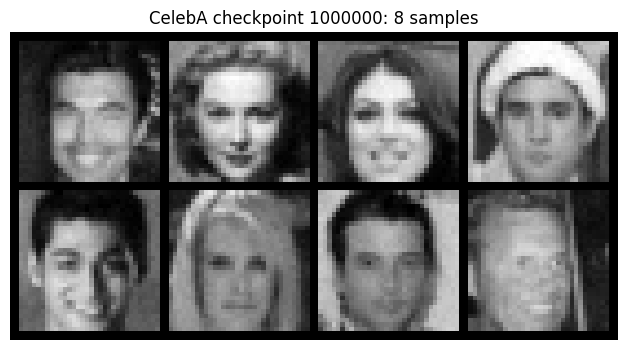

In [6]:
# Display the generated tensor as a four-by-two image grid.
samples = load_torch(step_dir / "samples.pt")
display_samples = (samples.clamp(-1, 1) + 1) / 2  # Convert [-1,1] to [0,1].
grid = make_grid(display_samples, nrow=4, padding=2)

plt.figure(figsize=(8, 4))
plt.imshow(grid.permute(1, 2, 0).numpy())
plt.axis("off")
plt.title(f"CelebA checkpoint {selected_step}: {len(samples)} samples")
plt.show()

## Saved artifacts

In [7]:
# Print the reusable sample, metric, and summary artifacts.
for path in (
    step_dir / "samples.pt",
    step_dir / "metrics.json",
    eval_dir / "combined" / "checkpoint_metrics.csv",
    eval_dir / "combined" / "summary.json",
):
    print(path)

/proj/rep-learning-robotics/users/x_moalj/project_mem_par/mem_param_clean/outputs/job_sets/celeba32_unet_3x3_1m/20260927T191224Z_2530324/runs/0_n512_x_x_s0/evaluations/notebook-celeba-step-1000000-n8-v1/checkpoints/step_1000000/samples.pt
/proj/rep-learning-robotics/users/x_moalj/project_mem_par/mem_param_clean/outputs/job_sets/celeba32_unet_3x3_1m/20260927T191224Z_2530324/runs/0_n512_x_x_s0/evaluations/notebook-celeba-step-1000000-n8-v1/checkpoints/step_1000000/metrics.json
/proj/rep-learning-robotics/users/x_moalj/project_mem_par/mem_param_clean/outputs/job_sets/celeba32_unet_3x3_1m/20260927T191224Z_2530324/runs/0_n512_x_x_s0/evaluations/notebook-celeba-step-1000000-n8-v1/combined/checkpoint_metrics.csv
/proj/rep-learning-robotics/users/x_moalj/project_mem_par/mem_param_clean/outputs/job_sets/celeba32_unet_3x3_1m/20260927T191224Z_2530324/runs/0_n512_x_x_s0/evaluations/notebook-celeba-step-1000000-n8-v1/combined/summary.json
